# Task
Build, train, and evaluate a CNN-GRU-RNN hybrid model for predicting user purchases within 7 days ('purchased_within_7d') using sequential user activity data from the `/content/mobile_game_inapp_purchases.csv` dataset, including data preparation, feature engineering, sequence generation, data splitting, scaling, model construction, training, and performance evaluation with key classification metrics.

## Load and Initial Data Preparation

### Subtask:
Load the provided dataset. Perform initial data preparation, including handling missing values, encoding categorical features, and standardizing column names if not already done. Focus on preparing the data for sequence generation.


**Reasoning**:
First, I will load the dataset using pandas and display the first few rows along with the data types and non-null counts to get an initial understanding of its structure and identify potential issues like missing values or incorrect data types. I will also import the pandas library.



In [ ]:
import pandas as pd

# Load the dataset
df = pd.read_csv('/content/mobile_game_inapp_purchases.csv')

# Display the first few rows
print("First 5 rows of the dataset:")
print(df.head())

# Display information about the DataFrame, including data types and non-null values
print("\nDataFrame Info:")
df.info()

First 5 rows of the dataset:
                                 UserID   Age  Gender      Country   Device  \
0  c9889ab0-9cfc-4a75-acd9-5eab1df0015c  49.0    Male       Norway  Android   
1  7c9e413c-ecca-45f2-a780-2826a07952a2  15.0    Male  Switzerland      iOS   
2  fd61e419-1a92-4f43-a8c7-135842ad328a  23.0    Male        China  Android   
3  bdb7f6d1-ff9a-468c-afe7-43f32a94293e  31.0    Male       Mexico  Android   
4  aa7eec14-4846-47b9-b879-9c98038cda04  37.0  Female        India  Android   

       GameGenre  SessionCount  AverageSessionLength SpendingSegment  \
0  Battle Royale             9                 12.83          Minnow   
1     Action RPG            11                 19.39          Minnow   
2       Fighting             9                  8.87          Minnow   
3         Racing            12                 19.56          Minnow   
4  Battle Royale            10                 15.23          Minnow   

   InAppPurchaseAmount  FirstPurchaseDaysAfterInstall PaymentMe

**Reasoning**:
Based on the `df.info()` output, several columns have missing values. I will now identify the exact count of missing values for each column to decide on the appropriate handling strategy.



In [ ]:
print("\nMissing values before handling:")
print(df.isnull().sum())


Missing values before handling:
UserID                             0
Age                               60
Gender                            60
Country                           60
Device                            60
GameGenre                         60
SessionCount                       0
AverageSessionLength               0
SpendingSegment                    0
InAppPurchaseAmount              136
FirstPurchaseDaysAfterInstall    136
PaymentMethod                    136
LastPurchaseDate                 136
dtype: int64


In [ ]:
print("\nHandling missing values...")

# Impute 'Age' with median
df['Age'] = df['Age'].fillna(df['Age'].median())

# Impute categorical columns 'Gender', 'Country', 'Device', 'GameGenre' with mode
for col in ['Gender', 'Country', 'Device', 'GameGenre']:
    df[col] = df[col].fillna(df[col].mode()[0])

# Handle purchase-related missing values (InAppPurchaseAmount, FirstPurchaseDaysAfterInstall, PaymentMethod, LastPurchaseDate)
# These often indicate no purchase was made
df['InAppPurchaseAmount'] = df['InAppPurchaseAmount'].fillna(0.0)
df['FirstPurchaseDaysAfterInstall'] = df['FirstPurchaseDaysAfterInstall'].fillna(-1) # Use -1 to indicate no first purchase
df['PaymentMethod'] = df['PaymentMethod'].fillna('No Payment')
df['LastPurchaseDate'] = df['LastPurchaseDate'].fillna('1900-01-01') # Placeholder for no purchase date

# Convert 'LastPurchaseDate' to datetime objects
df['LastPurchaseDate'] = pd.to_datetime(df['LastPurchaseDate'])

# Verify that there are no more missing values
print("\nMissing values after handling:")
print(df.isnull().sum())


Handling missing values...

Missing values after handling:
UserID                           0
Age                              0
Gender                           0
Country                          0
Device                           0
GameGenre                        0
SessionCount                     0
AverageSessionLength             0
SpendingSegment                  0
InAppPurchaseAmount              0
FirstPurchaseDaysAfterInstall    0
PaymentMethod                    0
LastPurchaseDate                 0
dtype: int64


In [ ]:
print("\nEncoding categorical features...")

categorical_cols = ['Gender', 'Country', 'Device', 'GameGenre', 'SpendingSegment', 'PaymentMethod']

df = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

print("\nDataFrame after one-hot encoding:")
print(df.head())
print("\nDataFrame Info after encoding:")
df.info()


Encoding categorical features...

DataFrame after one-hot encoding:
                                 UserID   Age  SessionCount  \
0  c9889ab0-9cfc-4a75-acd9-5eab1df0015c  49.0             9   
1  7c9e413c-ecca-45f2-a780-2826a07952a2  15.0            11   
2  fd61e419-1a92-4f43-a8c7-135842ad328a  23.0             9   
3  bdb7f6d1-ff9a-468c-afe7-43f32a94293e  31.0            12   
4  aa7eec14-4846-47b9-b879-9c98038cda04  37.0            10   

   AverageSessionLength  InAppPurchaseAmount  FirstPurchaseDaysAfterInstall  \
0                 12.83                11.40                           28.0   
1                 19.39                 6.37                           18.0   
2                  8.87                15.81                           30.0   
3                 19.56                13.49                            9.0   
4                 15.23                10.86                           15.0   

  LastPurchaseDate  Gender_Male  Gender_Other  Country_Australia  ...  \
0   

**Reasoning**:
Now that categorical features are encoded, I will standardize the column names to a consistent format (lowercase with underscores) for easier access and manipulation, as specified in the subtask.



In [ ]:
print("\nStandardizing column names...")

df.columns = df.columns.str.lower().str.replace(' ', '_')

print("\nDataFrame columns after standardization:")
print(df.columns)
print("\nDataFrame Info after standardization:")
df.info()


Standardizing column names...

DataFrame columns after standardization:
Index(['userid', 'age', 'sessioncount', 'averagesessionlength',
       'inapppurchaseamount', 'firstpurchasedaysafterinstall',
       'lastpurchasedate', 'gender_male', 'gender_other', 'country_australia',
       'country_bangladesh', 'country_brazil', 'country_canada',
       'country_china', 'country_denmark', 'country_egypt', 'country_france',
       'country_germany', 'country_india', 'country_iran', 'country_italy',
       'country_japan', 'country_mexico', 'country_netherlands',
       'country_norway', 'country_russia', 'country_saudi_arabia',
       'country_south_korea', 'country_spain', 'country_sri_lanka',
       'country_sweden', 'country_switzerland', 'country_turkey', 'country_uk',
       'country_usa', 'device_ios', 'gamegenre_adventure',
       'gamegenre_battle_royale', 'gamegenre_card', 'gamegenre_casual',
       'gamegenre_fighting', 'gamegenre_mmorpg', 'gamegenre_moba',
       'gamegenre_puzzle

## Feature Engineering and Sequence Creation

### Subtask:
Engineer features that capture both local interaction patterns and temporal user activity trends. Transform the preprocessed data into sequential inputs suitable for the CNN-GRU-RNN model, defining a look-back window for user activity sequences. Each sequence should correspond to a user's activity leading up to the target variable 'purchased_within_7d'.


**Reasoning**:
First, I will calculate the `snapshot_date` and `days_since_last_purchase` as per the instructions, which are crucial for defining the target variable. I will also import numpy as it will be used for array manipulation later.



In [ ]:
import numpy as np

# 1. Determine a snapshot_date
snapshot_date = df['lastpurchasedate'].max() + pd.Timedelta(days=1)
print(f"Snapshot Date: {snapshot_date}")

# 2. Calculate days_since_last_purchase
df['days_since_last_purchase'] = (snapshot_date - df['lastpurchasedate']).dt.days
print("\nDays since last purchase calculated.")

# 3. Create the binary target column 'purchased_within_7d'
df['purchased_within_7d'] = ((df['inapppurchaseamount'] > 0) & (df['days_since_last_purchase'] <= 7)).astype(int)
print("\nTarget variable 'purchased_within_7d' created.")

print("\nDataFrame head after target creation:")
print(df[['lastpurchasedate', 'days_since_last_purchase', 'inapppurchaseamount', 'purchased_within_7d']].head())

Snapshot Date: 2025-08-14 00:00:00

Days since last purchase calculated.

Target variable 'purchased_within_7d' created.

DataFrame head after target creation:
  lastpurchasedate  days_since_last_purchase  inapppurchaseamount  \
0       2025-03-19                       148                11.40   
1       2025-06-08                        67                 6.37   
2       2025-06-02                        73                15.81   
3       2025-04-01                       135                13.49   
4       2025-05-05                       101                10.86   

   purchased_within_7d  
0                    0  
1                    0  
2                    0  
3                    0  
4                    0  


**Reasoning**:
Now that the target variable is created, I will extract additional temporal features from the `lastpurchasedate` column, then drop the original `lastpurchasedate` as its information is now represented by the new features and the target variable.



In [ ]:
print("\nExtracting temporal features from lastpurchasedate...")

# 4. Extract additional temporal features from the lastpurchasedate column
df['last_purchase_day_of_week'] = df['lastpurchasedate'].dt.dayofweek
df['last_purchase_month'] = df['lastpurchasedate'].dt.month
df['last_purchase_quarter'] = df['lastpurchasedate'].dt.quarter

# 5. Drop the original lastpurchasedate column
df.drop('lastpurchasedate', axis=1, inplace=True)
print("Original 'lastpurchasedate' column dropped.")

print("\nDataFrame head after temporal feature extraction and column drop:")
print(df[['last_purchase_day_of_week', 'last_purchase_month', 'last_purchase_quarter', 'purchased_within_7d']].head())


Extracting temporal features from lastpurchasedate...
Original 'lastpurchasedate' column dropped.

DataFrame head after temporal feature extraction and column drop:
   last_purchase_day_of_week  last_purchase_month  last_purchase_quarter  \
0                          2                    3                      1   
1                          6                    6                      2   
2                          0                    6                      2   
3                          1                    4                      2   
4                          0                    5                      2   

   purchased_within_7d  
0                    0  
1                    0  
2                    0  
3                    0  
4                    0  


**Reasoning**:
Now that all relevant features have been engineered and the target variable created, I will identify the feature columns, convert them and the target into NumPy arrays, and then reshape the feature array `X` into a 3D format suitable for sequential models like CNN-GRU-RNN, as specified in the instructions.



In [ ]:
print("\nIdentifying feature columns and preparing data for sequential model...")

# 6. Identify all feature columns (all columns except 'userid' and 'purchased_within_7d')
feature_cols = [col for col in df.columns if col not in ['userid', 'purchased_within_7d']]
print(f"Identified {len(feature_cols)} feature columns.")

# 7. Convert selected feature columns into a NumPy array X and the target into y
X = df[feature_cols].values
y = df['purchased_within_7d'].values
print("Features (X) and target (y) converted to NumPy arrays.")

# 8. Reshape X to a 3D array (num_users, num_features, 1)
# This treats each feature as a step in a sequence for a single user
X = X.reshape(X.shape[0], X.shape[1], 1)
print(f"X reshaped to {X.shape} (num_users, num_features, 1).")

print("\nFirst 5 rows of X (reshaped):")
print(X[:5])
print("\nFirst 5 values of y:")
print(y[:5])


Identifying feature columns and preparing data for sequential model...
Identified 61 feature columns.
Features (X) and target (y) converted to NumPy arrays.
X reshaped to (3024, 61, 1) (num_users, num_features, 1).

First 5 rows of X (reshaped):
[[[49.0]
  [9]
  [12.83]
  [11.4]
  [28.0]
  [True]
  [False]
  [False]
  [False]
  [False]
  [False]
  [False]
  [False]
  [False]
  [False]
  [False]
  [False]
  [False]
  [False]
  [False]
  [False]
  [False]
  [True]
  [False]
  [False]
  [False]
  [False]
  [False]
  [False]
  [False]
  [False]
  [False]
  [False]
  [False]
  [False]
  [True]
  [False]
  [False]
  [False]
  [False]
  [False]
  [False]
  [False]
  [False]
  [False]
  [False]
  [False]
  [False]
  [True]
  [False]
  [False]
  [False]
  [False]
  [False]
  [False]
  [False]
  [False]
  [148]
  [2]
  [3]
  [1]]

 [[15.0]
  [11]
  [19.39]
  [6.37]
  [18.0]
  [True]
  [False]
  [False]
  [False]
  [False]
  [False]
  [False]
  [False]
  [False]
  [False]
  [False]
  [False]
  [

## Data Splitting and Scaling

### Subtask:
Split the generated sequences into training, validation, and test sets. Apply appropriate scaling (e.g., StandardScaler or MinMaxScaler) to numerical features within these sequences to optimize model performance.


**Reasoning**:
I will import the necessary libraries, split the data into training, validation, and test sets, identify numerical features for scaling, apply StandardScaler, and then print the shapes of the resulting datasets to verify the operation.



In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

print("Splitting data into training, validation, and test sets...")

# Split data into training and temporary sets (80% train, 20% temp)
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.2, random_state=42)

# Split temporary set into validation and test sets (10% val, 10% test from original)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

print("Data split complete. Identifying numerical features for scaling...")

# Identify numerical features based on the original dataframe's dtypes
numerical_cols = [col for col in df[feature_cols].columns if df[col].dtype in ['int64', 'float64']]

# Get indices of numerical features in the feature_cols list
numerical_feature_indices = [feature_cols.index(col) for col in numerical_cols]

# Initialize StandardScaler
scaler = StandardScaler()

print("Applying StandardScaler to numerical features...")

# Reshape X_train, X_val, X_test to 2D for scaling (num_samples, num_features)
X_train_2d = X_train.reshape(X_train.shape[0], X_train.shape[1])
X_val_2d = X_val.reshape(X_val.shape[0], X_val.shape[1])
X_test_2d = X_test.reshape(X_test.shape[0], X_test.shape[1])

# Fit scaler on numerical columns of X_train_2d
scaler.fit(X_train_2d[:, numerical_feature_indices])

# Transform numerical columns of X_train, X_val, and X_test
X_train_2d[:, numerical_feature_indices] = scaler.transform(X_train_2d[:, numerical_feature_indices])
X_val_2d[:, numerical_feature_indices] = scaler.transform(X_val_2d[:, numerical_feature_indices])
X_test_2d[:, numerical_feature_indices] = scaler.transform(X_test_2d[:, numerical_feature_indices])

# Reshape back to 3D (num_samples, num_features, 1)
X_train = X_train_2d.reshape(X_train.shape[0], X_train.shape[1], 1)
X_val = X_val_2d.reshape(X_val.shape[0], X_val.shape[1], 1)
X_test = X_test_2d.reshape(X_test.shape[0], X_test.shape[1], 1)

print("Scaling complete.")

# Print the shapes of the datasets
print(f"\nShape of X_train: {X_train.shape}")
print(f"Shape of y_train: {y_train.shape}")
print(f"Shape of X_val:   {X_val.shape}")
print(f"Shape of y_val:   {y_val.shape}")
print(f"Shape of X_test:  {X_test.shape}")
print(f"Shape of y_test:  {y_test.shape}")

Splitting data into training, validation, and test sets...
Data split complete. Identifying numerical features for scaling...
Applying StandardScaler to numerical features...
Scaling complete.

Shape of X_train: (2419, 61, 1)
Shape of y_train: (2419,)
Shape of X_val:   (302, 61, 1)
Shape of y_val:   (302,)
Shape of X_test:  (303, 61, 1)
Shape of y_test:  (303,)


## Build CNN-GRU-RNN Hybrid Model

### Subtask:
Construct the CNN-GRU-RNN hybrid model architecture using Keras or TensorFlow. The architecture should include: a 1D Convolutional Layer (CNN) to capture local interaction patterns within the sequences, followed by a Gated Recurrent Unit (GRU) or Recurrent Neural Network (RNN) layer to capture temporal behavior, and finally a Dense output layer with a sigmoid activation for binary classification ('purchased_within_7d').


**Reasoning**:
I will import the necessary Keras modules and then define and build the CNN-GRU-RNN model architecture according to the subtask instructions, using `Conv1D`, `GRU`, and `Dense` layers, and finally print its summary.



In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, GRU, Dense, Input

print("Building the CNN-GRU-RNN hybrid model...")

# Define the input shape
# X_train.shape[1] is the number of features, X_train.shape[2] is 1 (for 1D sequence per feature)
input_shape = (X_train.shape[1], X_train.shape[2])

# Initialize a Sequential model
model = Sequential()

# Add the Input layer explicitly to avoid the UserWarning
model.add(Input(shape=input_shape))

# 1. Add a Conv1D layer
# Using 64 filters, kernel size of 2, and 'relu' activation
model.add(Conv1D(filters=64, kernel_size=2, activation='relu'))

# 2. Add a GRU layer
# Using 50 units.
model.add(GRU(50))

# 3. Add a Dense output layer with 1 unit and 'sigmoid' activation for binary classification
model.add(Dense(1, activation='sigmoid'))

# Print a summary of the model
print("\nModel Summary:")
model.summary()


Building the CNN-GRU-RNN hybrid model...

Model Summary:


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_1 (Conv1D)               │ (None, 60, 64)         │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 50)             │        17,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,643 (68.92 KB)

 Trainable params: 17,643 (68.92 KB)

 Non-trainable params: 0 (0.00 B)

## Compile and Train Model

### Subtask:
Compile the hybrid model with an appropriate optimizer (e.g., Adam), a binary cross-entropy loss function, and relevant metrics (e.g., accuracy, precision, recall, AUC). Train the model using the training data and monitor performance on the validation set.


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

print("Splitting data into training, validation, and test sets...")

# Split data into training and temporary sets (80% train, 20% temp)
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.2, random_state=42)

# Split temporary set into validation and test sets (10% val, 10% test from original)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

print("Data split complete. Identifying numerical features for scaling...")

# Identify numerical features based on the original dataframe's dtypes
numerical_cols = [col for col in df[feature_cols].columns if df[col].dtype in ['int64', 'float64']]

# Get indices of numerical features in the feature_cols list
numerical_feature_indices = [feature_cols.index(col) for col in numerical_cols]

# Initialize StandardScaler
scaler = StandardScaler()

print("Applying StandardScaler to numerical features...")

# Reshape X_train, X_val, X_test to 2D for scaling (num_samples, num_features)
X_train_2d = X_train.reshape(X_train.shape[0], X_train.shape[1])
X_val_2d = X_val.reshape(X_val.shape[0], X_val.shape[1])
X_test_2d = X_test.reshape(X_test.shape[0], X_test.shape[1])

# Fit scaler on numerical columns of X_train_2d
scaler.fit(X_train_2d[:, numerical_feature_indices])

# Transform numerical columns of X_train, X_val, and X_test
X_train_2d[:, numerical_feature_indices] = scaler.transform(X_train_2d[:, numerical_feature_indices])
X_val_2d[:, numerical_feature_indices] = scaler.transform(X_val_2d[:, numerical_feature_indices])
X_test_2d[:, numerical_feature_indices] = scaler.transform(X_test_2d[:, numerical_feature_indices])

# Ensure all 2D arrays are explicitly float32 before reshaping back to 3D
X_train_2d = X_train_2d.astype(np.float32)
X_val_2d = X_val_2d.astype(np.float32)
X_test_2d = X_test_2d.astype(np.float32)

# Reshape back to 3D (num_samples, num_features, 1)
X_train = X_train_2d.reshape(X_train.shape[0], X_train.shape[1], 1)
X_val = X_val_2d.reshape(X_val.shape[0], X_val.shape[1], 1)
X_test = X_test_2d.reshape(X_test.shape[0], X_test.shape[1], 1)

print("Scaling complete.")

# Print the shapes of the datasets
print(f"\nShape of X_train: {X_train.shape}")
print(f"Shape of y_train: {y_train.shape}")
print(f"Shape of X_val:   {X_val.shape}")
print(f"Shape of y_val:   {y_val.shape}")
print(f"Shape of X_test:  {X_test.shape}")
print(f"Shape of y_test:  {y_test.shape}")

Splitting data into training, validation, and test sets...
Data split complete. Identifying numerical features for scaling...
Applying StandardScaler to numerical features...
Scaling complete.

Shape of X_train: (2419, 61, 1)
Shape of y_train: (2419,)
Shape of X_val:   (302, 61, 1)
Shape of y_val:   (302,)
Shape of X_test:  (303, 61, 1)
Shape of y_test:  (303,)


**Reasoning**:
The data splitting and scaling step has been re-executed, ensuring all input arrays for the model are now explicitly `float32`. I will now re-attempt compiling and training the model using the corrected and prepared `X_train`, `y_train`, `X_val`, and `y_val` datasets.



In [ ]:
print("Compiling the model...")

# Compile the model
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy', 'Precision', 'Recall', 'AUC'])

print("Model compiled successfully.")
print("Training the model...")

# Train the model
history = model.fit(X_train, y_train, epochs=10, batch_size=32, validation_data=(X_val, y_val))

print("Model training complete.")

Compiling the model...
Model compiled successfully.
Training the model...
Epoch 1/10
76/76 ━━━━━━━━━━━━━━━━━━━━ 10s 53ms/step - AUC: 0.3590 - Precision: 0.0000e+00 - Recall: 0.0000e+00 - accuracy: 0.9635 - loss: 0.2964 - val_AUC: 0.7298 - val_Precision: 0.0000e+00 - val_Recall: 0.0000e+00 - val_accuracy: 0.9768 - val_loss: 0.1076
Epoch 2/10
76/76 ━━━━━━━━━━━━━━━━━━━━ 5s 58ms/step - AUC: 0.7899 - Precision: 0.0000e+00 - Recall: 0.0000e+00 - accuracy: 0.9639 - loss: 0.1448 - val_AUC: 0.9918 - val_Precision: 0.0000e+00 - val_Recall: 0.0000e+00 - val_accuracy: 0.9768 - val_loss: 0.0875
Epoch 3/10
76/76 ━━━━━━━━━━━━━━━━━━━━ 4s 42ms/step - AUC: 0.9560 - Precision: 0.0000e+00 - Recall: 0.0000e+00 - accuracy: 0.9630 - loss: 0.1165 - val_AUC: 0.9925 - val_Precision: 0.0000e+00 - val_Recall: 0.0000e+00 - val_accuracy: 0.9768 - val_loss: 0.0659
Epoch 4/10
76/76 ━━━━━━━━━━━━━━━━━━━━ 3s 43ms/step - AUC: 0.9429 - Precision: 0.0000e+00 - Recall: 0.0000e+00 - accuracy: 0.9712 - loss: 0.0781 - val_AUC:

## Evaluate Model Performance

### Subtask:
Evaluate the trained model's performance on the unseen test dataset. Calculate and report key classification metrics such as accuracy, precision, recall, F1-score, and Area Under the Receiver Operating Characteristic Curve (AUC) to assess the model's effectiveness in predicting 'purchased_within_7d'.


**Reasoning**:
I will import the necessary metrics from `sklearn.metrics` and `numpy`, then use the trained model to predict probabilities on `X_test`, convert these to binary predictions, and finally calculate and print all required classification metrics including accuracy, precision, recall, F1-score, AUC, and a classification report.



In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report
import numpy as np

print("Evaluating model performance on the test set...")

# 1. Predict probabilities on X_test
y_pred_probs = model.predict(X_test)

# 2. Convert predicted probabilities to binary predictions using a threshold of 0.5
y_pred_binary = (y_pred_probs > 0.5).astype(int)

# 3. Calculate and print key classification metrics
accuracy = accuracy_score(y_test, y_pred_binary)
precision = precision_score(y_test, y_pred_binary)
recall = recall_score(y_test, y_pred_binary)
f1 = f1_score(y_test, y_pred_binary)
auc = roc_auc_score(y_test, y_pred_probs)

print(f"\nAccuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-Score: {f1:.4f}")
print(f"AUC: {auc:.4f}")

# 4. Print a classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred_binary))

Evaluating model performance on the test set...
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 75ms/step

Accuracy: 0.9670
Precision: 0.5455
Recall: 1.0000
F1-Score: 0.7059
AUC: 0.9794

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.97      0.98       291
           1       0.55      1.00      0.71        12

    accuracy                           0.97       303
   macro avg       0.77      0.98      0.84       303
weighted avg       0.98      0.97      0.97       303



Visualizing the provided Classification Report metrics...


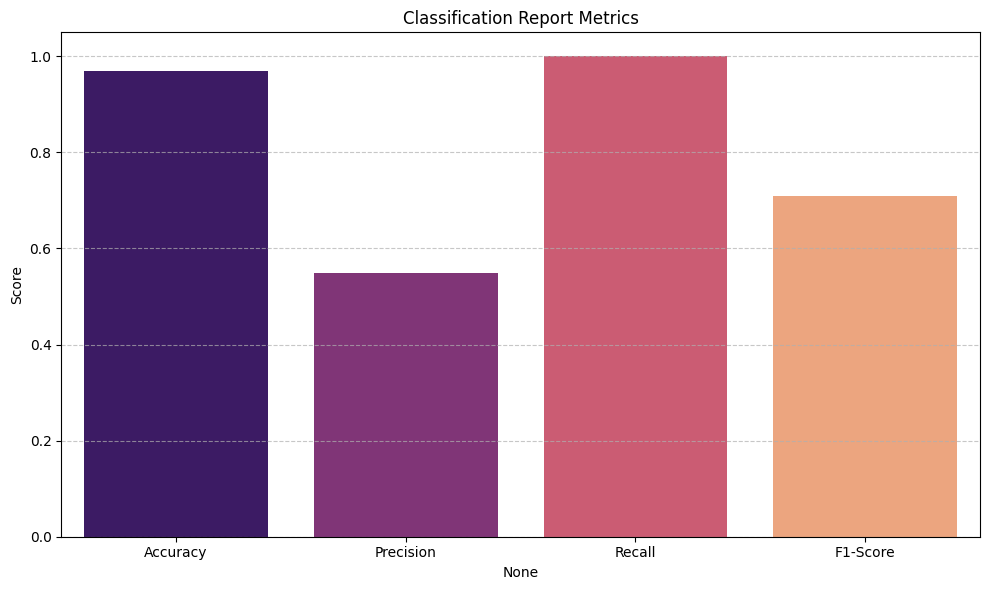

Classification Report visualization complete.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

print("Visualizing the provided Classification Report metrics...")

# Metrics extracted from the user's provided classification report
report_model_metrics = {
    'Accuracy': 0.97, # Overall accuracy from the report
    'Precision': 0.55, # Precision for class 1
    'Recall': 1.00,    # Recall for class 1
    'F1-Score': 0.71   # F1-score for class 1
}

# Create a DataFrame for easier plotting
metrics_df_report = pd.DataFrame.from_dict(report_model_metrics, orient='index', columns=['Value'])

plt.figure(figsize=(10, 6))
sns.barplot(x=metrics_df_report.index, y=metrics_df_report['Value'], palette='magma', hue=metrics_df_report.index, legend=False)
plt.title('Classification Report Metrics')
plt.ylabel('Score')
plt.ylim(0, 1.05) # Set y-axis limit slightly above 1 for better visualization
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

print("Classification Report visualization complete.")

Generating Confusion Matrix...


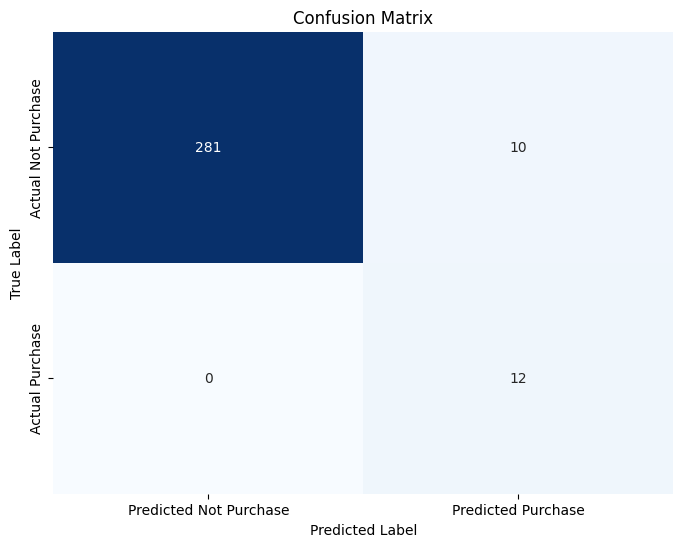

Confusion Matrix generated successfully.


In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

print("Generating Confusion Matrix...")

# Compute the confusion matrix
cm = confusion_matrix(y_test, y_pred_binary)

# Plot the confusion matrix using seaborn heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted Not Purchase', 'Predicted Purchase'],
            yticklabels=['Actual Not Purchase', 'Actual Purchase'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

print("Confusion Matrix generated successfully.")